# Elevator simulation

A simulation of a multiple elevators operating efficiently in a tall busy building

In [128]:
# parameteric inputs
nFloors = 100
nPassengerIds = 1000
capacityPerElevator = 8
nElevators = 6

expressRoutes = {}
# expressRoutes = { # optional
#     1: {0, 25, 50},      # elevator 1
#     3: {0, 50, 75, 99},  # elevator 3
# }

# program params
input_data_fn = "input.csv"
elevator_position_history_fn = "out/elevator_positions_log.csv"
summary_stats_fn = "out/passenger_summary_stats.csv"

nTimeSteps:int   # will be set based on input data length


In [129]:
# imports
import pandas as pd
import statistics
import matplotlib.pyplot as plt

# built-ins
from typing import List, Literal, TypedDict
from math import exp

In [130]:
# load input data
input_data = pd.read_csv(input_data_fn)

nTimeSteps = int(input_data.iloc[-1, 0])
print("number of time steps:", nTimeSteps)

# print(input_data)


number of time steps: 999


In [131]:
# validate input parameters
assert nFloors > 0, "Number of floors must be positive"
assert nPassengerIds > 0, "Number of passenger IDs must be positive"
assert capacityPerElevator > 0, "Capacity per elevator must be positive"
assert nElevators > 0, "Number of elevators must be positive"
assert nTimeSteps > 0, "Number of time steps must be positive"

# ensure express routes are valid
for elevator, floors in expressRoutes.items():
    assert 0 <= elevator < nElevators, f"Elevator {elevator} is out of range"
    for floor in floors:
        assert 0 <= floor < nFloors, f"Floor {floor} for elevator {elevator} is out of range"

In [132]:
# initialise the elevator position output data structure
elevator_position_history = pd.DataFrame({
    "time": range(nTimeSteps),
    **{f"elevator{i}": [0] * nTimeSteps for i in range(nElevators)}, # assumption: all elevators start on floor 0
}, dtype=int)

elevator_position_history.to_csv(elevator_position_history_fn, index=False)

In [133]:
# a typesafe dict data structure for keeping track of active elevator requests
class ElevatorRequest(TypedDict):
    time: int
    passenger_id: str
    source: int
    dest: int
    status: Literal["waiting", "travelling"]
    elevator: int | None

active_requests: list[ElevatorRequest] = []

# a data structure for keeping track of elevator states
ElevatorStatus = Literal["STOPPED", "RISING", "FALLING"]
class Elevator(TypedDict):
    status: ElevatorStatus
    occupants: int
    floor: int

elevatorStates: list[list[Elevator]] = []

# a dictionary to keep track of wait times for each passenger
wait_times: dict[str, list[int]] = {}

# a list to keep track of elevator full events
elevator_full_events: list[tuple[int,int]] = []


In [134]:
### strategies

# this strategy does nothing and always returns floor 0
def strategy_nop() -> list[Elevator]:
    """Create the initial stopped state for each elevator."""
    return [Elevator(floor=0, occupants=0, status="STOPPED") for _ in range(nElevators)]


# this strategy naively scans up and down the elevator shafts (from floor 0 to nFloors-1) and picks up/drops off passengers as it goes
def strategy_scan(
    currentElevatorStates: list[Elevator],
    active_requests: list[ElevatorRequest],
) -> list[Elevator]:
    """Move elevators between the ground and top floors."""

    # move the elevators up or down depending on their current RISING/FALLING status:
    nextElevatorStates: list[Elevator] = []
    for currentElevatorState in currentElevatorStates:
        nextElevatorState = currentElevatorState.copy()
        if nextElevatorState["status"] == "FALLING":
            nextElevatorState["floor"] -= 1
            if nextElevatorState["floor"] == 0:
                nextElevatorState["status"] = "RISING"
        else:
            nextElevatorState["floor"] += 1
            if nextElevatorState["floor"] == nFloors - 1:
                nextElevatorState["status"] = "FALLING"
            else:
                nextElevatorState["status"] = "RISING"
        nextElevatorStates.append(nextElevatorState)

    # Reassign waiting passengers to the nearest elevator every step
    for request in active_requests:
        if request["status"] == "waiting":
            request["elevator"] = min(
                (i for i in range(nElevators) if can_serve(i, request)),
                key=lambda i: abs(currentElevatorStates[i]["floor"] - request["source"]),
            )

    board_alight_passengers(currentElevatorStates, nextElevatorStates, active_requests)

    return nextElevatorStates


# this strategy (less naively) assigns the nearest elevator to each waiting passenger and picks up/drops off passengers as it goes. Elevators stop moving when not needed.
def strategy_intelligent(
    currentElevatorStates: list[Elevator],
    active_requests: list[ElevatorRequest],
) -> list[Elevator]:
    """Dispatch elevators on demand: each elevator moves one floor per step
    towards its nearest stop (drop-offs of passengers aboard, plus assigned
    pickups while it has room) and idles (STOPPED) when it has no work."""

    # Sticky assignment — each new waiting request is assigned once to the closest elevator (instead of being reassigned every step)
    # Targeted movement — each elevator collects its stops: destinations of passengers aboard, plus sources of its assigned pickups (only while it has spare capacity). It moves one floor per step toward the nearest stop and sets RISING/FALLING accordingly
    # Idle when unneeded — an elevator with no work stays where it is with status STOPPED
    # Full-elevator recovery — if an elevator is full at pickup time, the request's assignment is released so a different elevator can claim it next step

    # assign each unassigned waiting request to the closest elevator (sticky assignment)
    for request in active_requests:
        if request["status"] == "waiting" and (request["elevator"] is None or not can_serve(request["elevator"], request)):
            request["elevator"] = min(
                (i for i in range(nElevators) if can_serve(i, request)),
                key=lambda i: abs(currentElevatorStates[i]["floor"] - request["source"]),
            )

    # move the elevators (pause, up, down) from their current positions depending on the demand:
    nextElevatorStates: list[Elevator] = []
    for i, currentElevatorState in enumerate(currentElevatorStates):
        nextElevatorState = currentElevatorState.copy()
        floor = currentElevatorState["floor"]

        dropoffs = [r["dest"] for r in active_requests
                    if r["status"] == "travelling" and r["elevator"] == i]
        pickups = [r["source"] for r in active_requests
                   if r["status"] == "waiting" and r["elevator"] == i]

        # only chase new pickups while there is room on board
        targets = dropoffs + (pickups if currentElevatorState["occupants"] < capacityPerElevator else [])

        if targets:
            target = min(targets, key=lambda f: abs(f - floor))
            if target > floor:
                nextElevatorState["floor"] = floor + 1
                nextElevatorState["status"] = "RISING"
            elif target < floor:
                nextElevatorState["floor"] = floor - 1
                nextElevatorState["status"] = "FALLING"
            else:
                nextElevatorState["status"] = "STOPPED"
        else:
            # no demand for this elevator: idle where it is
            nextElevatorState["status"] = "STOPPED"
        nextElevatorStates.append(nextElevatorState)

    # Now process passenger stops, keeping the sticky elevator assignments
    board_alight_passengers(currentElevatorStates, nextElevatorStates, active_requests)

    return nextElevatorStates

# elevators operated in their own zones (pick up passengers in designated floor ranges, drop off anywhere)
def strategy_zoneBased(currentElevatorStates: list[Elevator], active_requests: list[ElevatorRequest]) -> list[Elevator]:
    """Prefer the pickup zone owner, falling back to the nearest eligible elevator."""

    nextElevatorStates: list[Elevator] = []
    nElevators = len(currentElevatorStates)
    for request in active_requests:
        if request["status"] == "waiting" and (request["elevator"] is None or not can_serve(request["elevator"], request)):
            zone_owner = request["source"] * nElevators // nFloors
            request["elevator"] = min(
                (i for i in range(nElevators) if can_serve(i, request)),
                key=lambda i: (i != zone_owner, abs(currentElevatorStates[i]["floor"] - request["source"])),
            )

    for i, currentElevatorState in enumerate(currentElevatorStates):
        nextElevatorState = currentElevatorState.copy()
        floor = currentElevatorState["floor"]

        dropoffs = [r["dest"] for r in active_requests
                    if r["status"] == "travelling" and r["elevator"] == i]
        pickups = [r["source"] for r in active_requests
                   if r["status"] == "waiting" and r["elevator"] == i]

        targets = dropoffs + (pickups if currentElevatorState["occupants"] < capacityPerElevator else [])

        if targets:
            target = min(targets, key=lambda f: abs(f - floor))
            if target > floor:
                nextElevatorState["floor"] = floor + 1
                nextElevatorState["status"] = "RISING"
            elif target < floor:
                nextElevatorState["floor"] = floor - 1
                nextElevatorState["status"] = "FALLING"
            else:
                nextElevatorState["status"] = "STOPPED"
        else:
            nextElevatorState["status"] = "STOPPED"

        nextElevatorStates.append(nextElevatorState)

    board_alight_passengers(currentElevatorStates, nextElevatorStates, active_requests)
    return nextElevatorStates

In [135]:
# shared logic: process passenger stops, pausing each stopping elevator for at most one step
def board_alight_passengers(
    currentElevatorStates: list[Elevator],
    nextElevatorStates: list[Elevator],
    active_requests: list[ElevatorRequest],
) -> None:
    """Board/alight passengers, holding each stopping elevator at its floor for one step.

    A full elevator releases the request so it can be assigned again.
    Mutates nextElevatorStates, active_requests and wait_times in place.
    """
    elevators_to_pause: set[int] = set()
    for request in active_requests:
        if request["status"] == "waiting":
            elevator_index = request["elevator"]
            if elevator_index is not None and currentElevatorStates[elevator_index]["floor"] == request["source"]:
                if nextElevatorStates[elevator_index]["occupants"] < capacityPerElevator: # lt (check happens *before* the passenger boards)
                    request["status"] = "travelling"
                    elevators_to_pause.add(elevator_index)
                    nextElevatorStates[elevator_index]["occupants"] += 1
                else:
                    request["elevator"] = None
                    print(f"{t}: Elevator {elevator_index} is full, cannot pick up passenger {request['passenger_id']}")
                    elevator_full_events.append((t, elevator_index)) # log the elevator full event
        elif request["status"] == "travelling":
            elevator_index = request["elevator"]
            if elevator_index is not None and currentElevatorStates[elevator_index]["floor"] == request["dest"]:
                elevators_to_pause.add(elevator_index)
                nextElevatorStates[elevator_index]["occupants"] -= 1
                active_requests.remove(request)
                # wait_times stats (passenger has reached their destination):
                if request["passenger_id"] not in wait_times:
                    wait_times[request["passenger_id"]] = []
                wait_times[request["passenger_id"]].append(t - request["time"])

    # Hold at the current floor once - several passengers can board/exit during the same epoch
    for elevator_index in elevators_to_pause:
        nextElevatorStates[elevator_index]["floor"] = currentElevatorStates[elevator_index]["floor"]
        # print(nextElevatorStates[elevator_index]["occupants"])

# express elevator helper function
# Express elevators must serve both endpoints
def can_serve(i: int, request: ElevatorRequest) -> bool:
    """Unlisted elevators serve all floors; express elevators must serve both endpoints."""
    stops = expressRoutes.get(i)
    return stops is None or {request["source"], request["dest"]} <= stops


In [136]:
wait_times.clear()
currentElevatorStates: list[Elevator] = [Elevator(floor=0, occupants=0, status="STOPPED") for _ in range(nElevators)]
nextElevatorStates: list[Elevator] = []

# loop through the input data and position the elevators efficiently
for t in range(nTimeSteps):
    # Record the elevator positions at the start of this epoch.
    elevatorStates.append([state.copy() for state in currentElevatorStates])

    # is there a request in this epoch?
    if t in input_data["time"].values:
        requests_at_t = input_data[input_data["time"] == t]
        for _, row in requests_at_t.iterrows():
            passenger_id = row["passenger_id"]
            active_requests.append({ # any existing request for a passengerwill be overwritten
                "time": row["time"],
                "passenger_id": row["passenger_id"],
                "source": row["source"],
                "dest": row["dest"],
                "status": "waiting",
                "elevator": None
            })
    
    # # Always update elevator positions for time t
    # for elevator in range(nElevators):
    
    # no-op strategy: keep elevators at floor 0 for now
    # nextElevatorStates = strategy_nop()

    # naive scan
    # nextElevatorStates = strategy_scan(currentElevatorStates, active_requests)

    # more intelligent
    # nextElevatorStates = strategy_intelligent(currentElevatorStates, active_requests)

    # zone-based strategy
    nextElevatorStates = strategy_zoneBased(currentElevatorStates, active_requests)
    
    # Advance to the next epoch's elevator positions.
    currentElevatorStates = nextElevatorStates

elevator_position_history = pd.DataFrame(
    [[elevator["floor"] for elevator in states] for states in elevatorStates],
    columns=[f"elevator_{i}" for i in range(nElevators)]
)
elevator_position_history.to_csv(elevator_position_history_fn, index=False)
# print(elevator_position_history)

# print(currentElevatorStates)

150: Elevator 0 is full, cannot pick up passenger passenger101
151: Elevator 0 is full, cannot pick up passenger passenger101
164: Elevator 0 is full, cannot pick up passenger passenger144
164: Elevator 0 is full, cannot pick up passenger passenger109
178: Elevator 0 is full, cannot pick up passenger passenger144
178: Elevator 0 is full, cannot pick up passenger passenger109
183: Elevator 0 is full, cannot pick up passenger passenger109
184: Elevator 0 is full, cannot pick up passenger passenger109
185: Elevator 0 is full, cannot pick up passenger passenger216
186: Elevator 0 is full, cannot pick up passenger passenger416
192: Elevator 0 is full, cannot pick up passenger passenger999
193: Elevator 0 is full, cannot pick up passenger passenger386
193: Elevator 0 is full, cannot pick up passenger passenger96
217: Elevator 0 is full, cannot pick up passenger passenger53
232: Elevator 0 is full, cannot pick up passenger passenger454
236: Elevator 0 is full, cannot pick up passenger passeng

Summary stats for elevator wait times (including ride time)
Overall average wait time: 47.55
[min,max] wait time: [3, 164]
Overall total wait time: 11982
Assuming Gaussian distribution for wait times
Wait time standard deviation: 32.84
Wait time variance: 1078.22
Wait time median: 41.0
Wait time standard error: 2.07
Wait time confidence interval (95%): [43.49, 51.6]
Elevator full events:
Total elevator full events: 130
	t=150: Elevator 0 was full
	t=151: Elevator 0 was full
	t=164: Elevator 0 was full
	t=164: Elevator 0 was full
	t=178: Elevator 0 was full
	t=178: Elevator 0 was full
	t=183: Elevator 0 was full
	t=184: Elevator 0 was full
	t=185: Elevator 0 was full
	t=186: Elevator 0 was full
	t=192: Elevator 0 was full
	t=193: Elevator 0 was full
	t=193: Elevator 0 was full
	t=217: Elevator 0 was full
	t=232: Elevator 0 was full
	t=236: Elevator 0 was full
	t=237: Elevator 0 was full
	t=248: Elevator 0 was full
	t=248: Elevator 0 was full
	t=248: Elevator 0 was full
	t=248: Elevator 

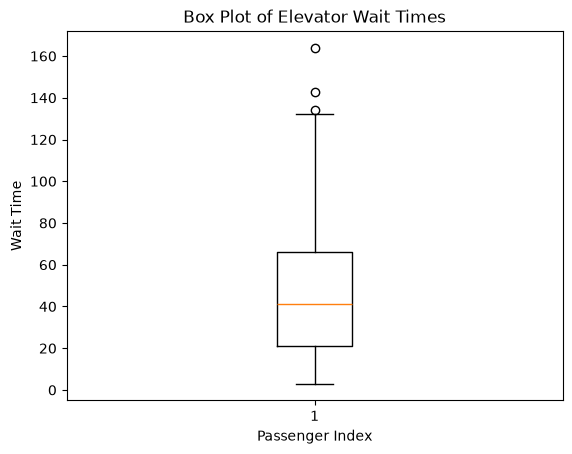

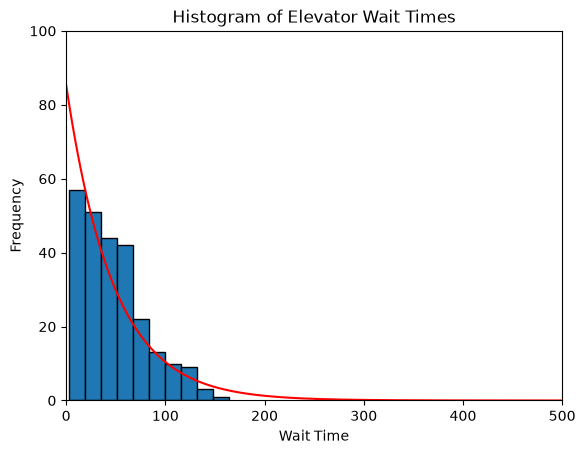

In [137]:
## summary stats
print("Summary stats for elevator wait times (including ride time)")

# print per-passenger summary stats: 
# for passenger_id, times in sorted(wait_times.items()):
#     print(f"Passenger {passenger_id}\n\twait times: {times}")
#     if times:
#         print(f"\taverage wait time: {sum(times) / len(times)}")
#         print(f"\ttotal wait time: {sum(times)}")

# print overall summary stats
total_wait_times = [sum(times) for times in wait_times.values() if times]
if total_wait_times:
    print(f"Overall average wait time: {round(sum(total_wait_times) / len(total_wait_times), 2)}")
    print(f"[min,max] wait time: [{min(total_wait_times)}, {max(total_wait_times)}]")
    print(f"Overall total wait time: {sum(total_wait_times)}")

# other notable stats about time distributsions/system behaviour:
print("Assuming Gaussian distribution for wait times")
if total_wait_times:
    print(f"Wait time standard deviation: {round(statistics.stdev(total_wait_times), 2)}")
    print(f"Wait time variance: {round(statistics.variance(total_wait_times), 2)}")
    print(f"Wait time median: {round(statistics.median(total_wait_times), 2)}")
    print(f"Wait time standard error: {round(statistics.stdev(total_wait_times) / (len(total_wait_times) ** 0.5), 2)}")
    print(f"Wait time confidence interval (95%): [{round(statistics.mean(total_wait_times) - 1.96 * (statistics.stdev(total_wait_times) / (len(total_wait_times) ** 0.5)), 2)}, {round(statistics.mean(total_wait_times) + 1.96 * (statistics.stdev(total_wait_times) / (len(total_wait_times) ** 0.5)), 2)}]")

# other observations:
print("Elevator full events:")
print(f"Total elevator full events: {len(elevator_full_events)}")
for event in elevator_full_events:
    print(f"\tt={event[0]}: Elevator {event[1]} was full")

# draw a box plot:
if total_wait_times:
    plt.boxplot(total_wait_times)
    plt.title("Box Plot of Elevator Wait Times")
    plt.xlabel("Passenger Index")
    plt.ylabel("Wait Time")
    plt.show()

# draw a histogram
if total_wait_times:
    plt.title("Histogram of Elevator Wait Times")
    plt.xlabel("Wait Time")
    plt.ylabel("Frequency")
    plt.xlim(0, 500)
    plt.ylim(0,100)
    # overlay exponential fit for the histogram:
    _, bins, _ = plt.hist(total_wait_times, bins=10, edgecolor='black')
    scale = statistics.mean(total_wait_times)
    x = range(1001)
    plt.plot(x, [len(total_wait_times) * (bins[1] - bins[0]) / scale * exp(-v / scale) for v in x], 'r-')

    plt.show()